# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

In [1]:
# Preliminares
import pandas as pd
from pathlib import Path
from src.config import carpeta_datos
from src.reg_modeling import cargar_datos
from src.transform import categorizar_en_cuantiles
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    pintar_matriz_correlacion 
)

# Cargar fichero de precios
simbolo = 'SPY'
intervalo = '1d'
df, cols_exclude = cargar_datos(simbolo=simbolo, intervalo=intervalo, leer_cols_exclude=True)
df_clean = df.drop(columns=cols_exclude)
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5187 entries, 2006-03-16 00:00:00-05:00 to 2026-10-27 00:00:00-04:00
Data columns (total 13 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Close_lag1_sma20_pct_diff_Close_lag1_sma50  5187 non-null   float64
 1   Volume_lag1_pct_diff_Volume_lag1_sma20      5187 non-null   float64
 2   Close_lag1_min20_pct_diff_Open              5187 non-null   float64
 3   High_pct_diff_Open                          5187 non-null   float64
 4   Low_pct_diff_Open                           5187 non-null   float64
 5   Close_pct_diff_Open                         5187 non-null   float64
 6   Low_lag1_pct_diff_Open                      5187 non-null   float64
 7   Close_lag1_pct_diff_Open                    5187 non-null   float64
 8   Close_lag1_sma50_pct_diff_Open              5187 non-null   float64
 9   Daily_return_lag1                    

## Analisis de variables

In [2]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

In [3]:
# Descripcion de variables
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Close_lag1_sma20_pct_diff_Close_lag1_sma50,5187.0,0.006334,0.024620,-0.148874,-0.003608,0.010523,0.020876,0.073720
Volume_lag1_pct_diff_Volume_lag1_sma20,5187.0,0.015703,0.378023,-0.828455,-0.232417,-0.060740,0.165571,3.319121
Close_lag1_min20_pct_diff_Open,5187.0,-0.034591,0.027386,-0.218761,-0.047607,-0.031493,-0.016677,0.076136
High_pct_diff_Open,5187.0,0.005958,0.006941,0.000000,0.001892,0.004069,0.007651,0.111827
Low_pct_diff_Open,5187.0,-0.006465,0.007459,-0.096852,-0.008325,-0.004292,-0.001829,0.000000
Close_pct_diff_Open,5187.0,0.000155,0.009356,-0.089906,-0.003558,0.000574,0.004454,0.111827
Low_lag1_pct_diff_Open,5187.0,-0.006853,0.010083,-0.140878,-0.010197,-0.005465,-0.001843,0.058125
Close_lag1_pct_diff_Open,5187.0,-0.000276,0.007388,-0.057782,-0.003421,-0.000583,0.002371,0.116676
Close_lag1_sma50_pct_diff_Open,5187.0,-0.009132,0.043737,-0.132745,-0.034650,-0.018036,0.004852,0.403590
Daily_return_lag1,5187.0,0.000488,0.012120,-0.109424,-0.003964,0.000693,0.005910,0.145198


In [4]:
# Asimetrias
mostrar_asimetrias(df_clean)

High_pct_diff_Open                            4.243025
Close_lag1_sma50_pct_diff_Open                2.728565
Volume_lag1_pct_diff_Volume_lag1_sma20        1.987384
Close_lag1_pct_diff_Open                      1.720330
Daily_return_lag1_var20_log                   0.653367
Close_lag1_max20_pct_diff_Open_yeo            0.457310
Daily_return_lag1                            -0.001335
Close_pct_diff_Open                          -0.025674
High_lag1_pct_diff_Open_yeo                  -0.506709
Close_lag1_min20_pct_diff_Open               -1.471492
Close_lag1_sma20_pct_diff_Close_lag1_sma50   -1.798073
Low_lag1_pct_diff_Open                       -2.393148
Low_pct_diff_Open                            -3.436527


Cont


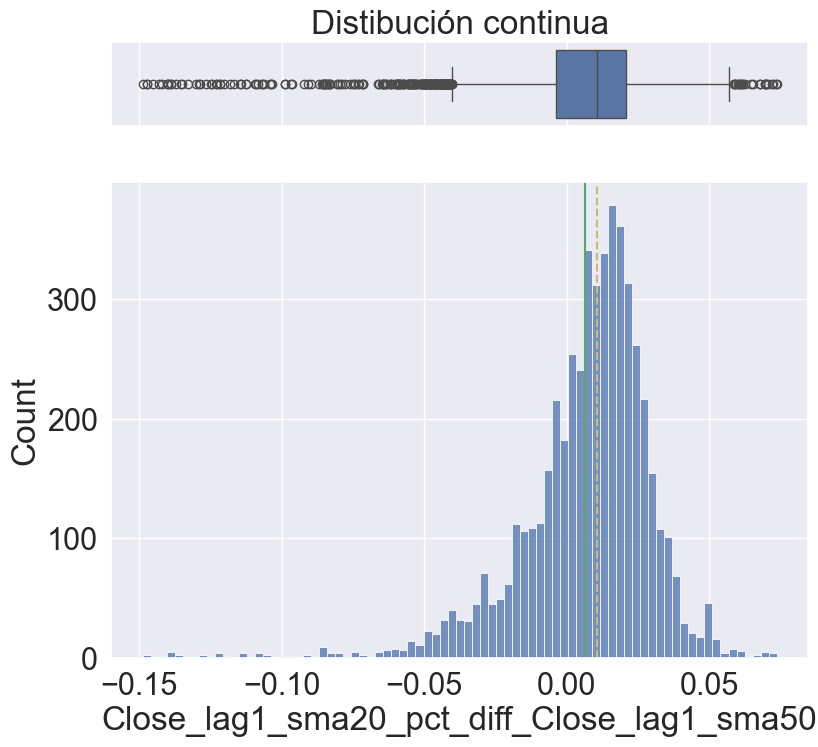

In [5]:
# Visualizar columna
col = 'Close_lag1_sma20_pct_diff_Close_lag1_sma50'
pintar_columna(df_clean[col])

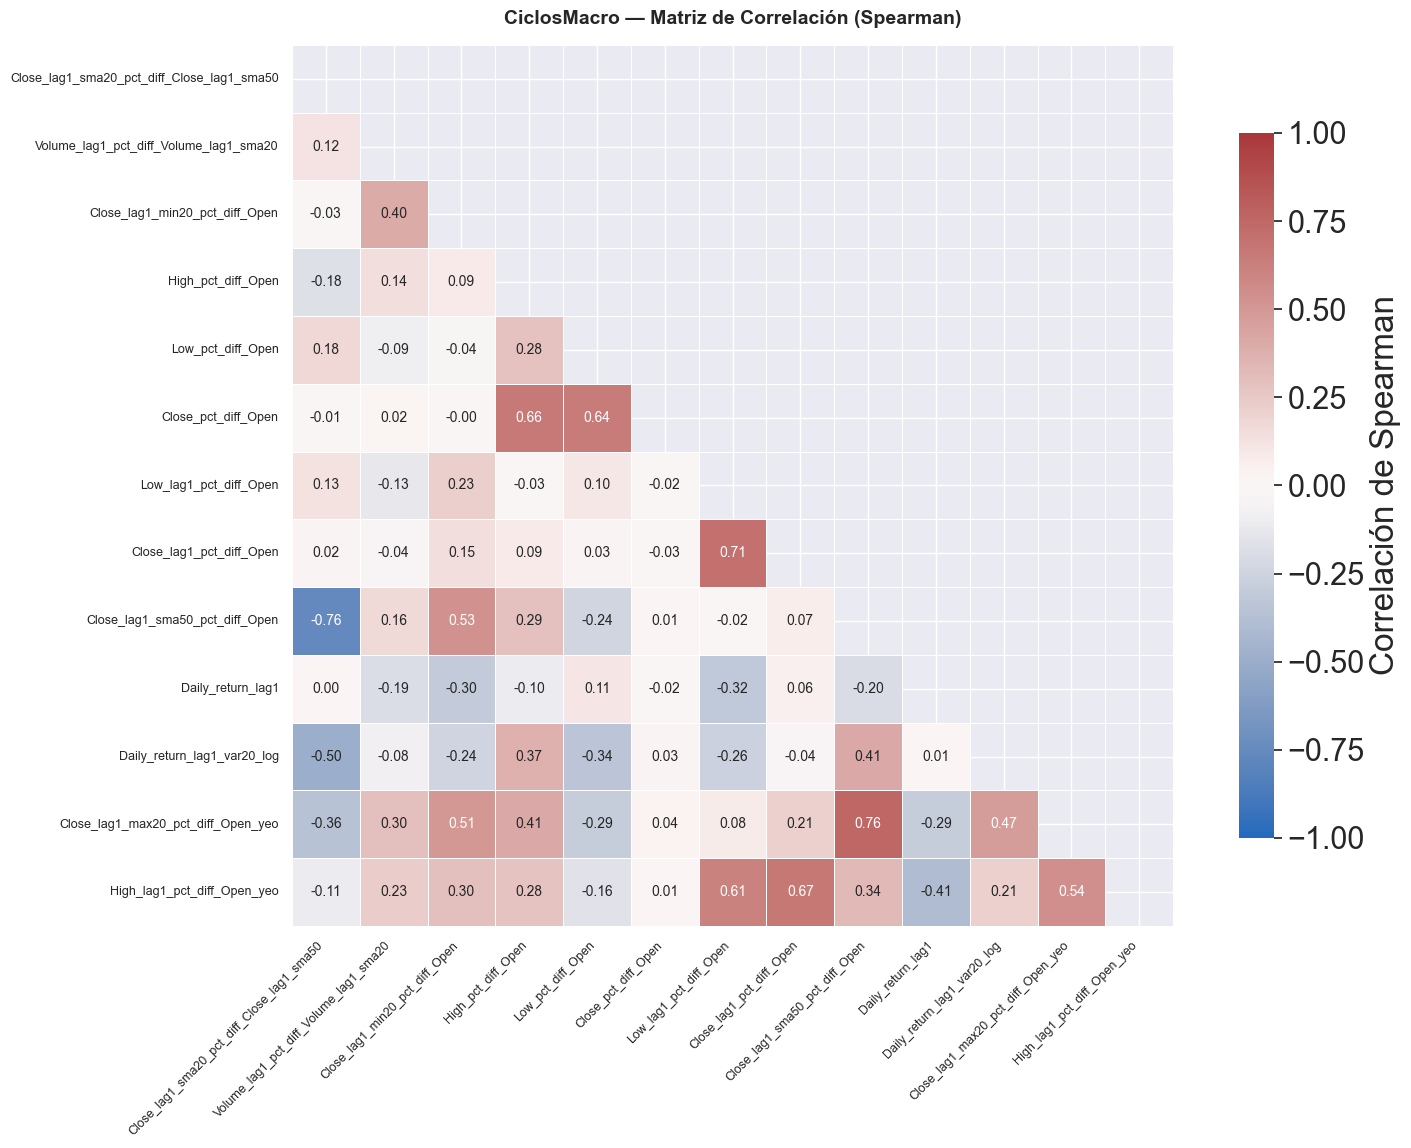

(                                            Close_lag1_sma20_pct_diff_Close_lag1_sma50  \
 Close_lag1_sma20_pct_diff_Close_lag1_sma50                                    1.000000   
 Volume_lag1_pct_diff_Volume_lag1_sma20                                        0.119597   
 Close_lag1_min20_pct_diff_Open                                               -0.029607   
 High_pct_diff_Open                                                           -0.177223   
 Low_pct_diff_Open                                                             0.177830   
 Close_pct_diff_Open                                                          -0.006177   
 Low_lag1_pct_diff_Open                                                        0.131653   
 Close_lag1_pct_diff_Open                                                      0.024596   
 Close_lag1_sma50_pct_diff_Open                                               -0.761313   
 Daily_return_lag1                                                             0.001801   

In [6]:
# Matriz de correlacion
pintar_matriz_correlacion(df_clean)

* `Close_pct_diff_Open` presenta escasa correlacion con los predictores, siendo el posible label mas debil.

## Analisis de labels

In [7]:
posibles_labels = ['High_pct_diff_Open', 'Low_pct_diff_Open', 'Close_pct_diff_Open']

objetivo = 'High_pct_diff_Open'
objetivo_cat = f"{objetivo}_cat"

df_clean, tabla_bins = categorizar_en_cuantiles(
    df_clean, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=False
    )

print("\n--- Rangos por Categoría ---")
print(tabla_bins)


--- Rangos por Categoría ---
   categoria  lim_inferior  lim_superior
0          1      0.000000      0.002572
1          2      0.002572      0.006191
2          3      0.006191      0.111827


In [9]:
df_clean[objetivo_cat].value_counts()

High_pct_diff_Open_cat
1    1729
2    1729
3    1729
Name: count, dtype: int64